In [36]:
from langchain_community.document_loaders import TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_core.prompts import PromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_groq import ChatGroq
import pandas as pd
import os
from langchain_core.documents import Document

In [37]:
groq_api_key = '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'

In [38]:
folder_path = "C:/Users/Kannan T/Documents/Mapping_files"

for file_name in os.listdir(folder_path):

    if file_name.endswith(".xlsx"):

        file_path = os.path.join(folder_path, file_name)

        # Read all sheets
        all_sheets = pd.read_excel(
            file_path,
            sheet_name=None
        )
    print(all_sheets.items())

dict_items([('BANCS Attribute map',          Mapping Object Name (EDL) Mapping Object Attribute (EDL)  \
0    cif_notification_subscription                notification_id   
1    cif_notification_subscription                       activity   
2    cif_notification_subscription                    activity_cd   
3    cif_notification_subscription                  activity_desc   
4    cif_notification_subscription                       currency   
..                             ...                            ...   
839                 mandate_matrix         customer_category_desc   
840                 mandate_matrix                      branch_id   
841                 mandate_matrix                  customer_name   
842                 mandate_matrix                registered_name   
843                 mandate_matrix                      entity_id   

     Owner business Object Owner Object Attribute  
0    CIF_NOTIFCN_SUBSCRPTN        notification_id  
1    CIF_NOTIFCN_SUBSCRPTN     

In [39]:
folder_path = "C:/Users/Kannan T/Documents/Mapping_files"

documents = []

for file_name in os.listdir(folder_path):

    if file_name.endswith(".xlsx"):

        file_path = os.path.join(folder_path, file_name)

        # Read all sheets
        all_sheets = pd.read_excel(
            file_path,
            sheet_name=None
        )

        for sheet_name, df in all_sheets.items():

            for _, row in df.iterrows():

                content = f"""
Owner Business Object: {row['Owner business Object']}
Owner Object Attribute: {row['Owner Object Attribute']}
EDL Object Name: {row['Mapping Object Name (EDL)']}
EDL Object Attribute: {row['Mapping Object Attribute (EDL)']}
"""

                documents.append(
                    Document(
                        page_content=content,
                        metadata={
                            "source_file": file_name,
                            "sheet_name": sheet_name
                        }
                    )
                )

print("Total documents:", len(documents))

Total documents: 2564


In [40]:
documents

[Document(metadata={'source_file': 'CIF_Mapping_Sheet.xlsx', 'sheet_name': 'BANCS Attribute map'}, page_content='\nOwner Business Object: CIF_NOTIFCN_SUBSCRPTN\nOwner Object Attribute: notification_id\nEDL Object Name: cif_notification_subscription\nEDL Object Attribute: notification_id\n'),
 Document(metadata={'source_file': 'CIF_Mapping_Sheet.xlsx', 'sheet_name': 'BANCS Attribute map'}, page_content='\nOwner Business Object: CIF_NOTIFCN_SUBSCRPTN\nOwner Object Attribute: activity\nEDL Object Name: cif_notification_subscription\nEDL Object Attribute: activity\n'),
 Document(metadata={'source_file': 'CIF_Mapping_Sheet.xlsx', 'sheet_name': 'BANCS Attribute map'}, page_content='\nOwner Business Object: CIF_NOTIFCN_SUBSCRPTN\nOwner Object Attribute: activity_cd\nEDL Object Name: cif_notification_subscription\nEDL Object Attribute: activity_cd\n'),
 Document(metadata={'source_file': 'CIF_Mapping_Sheet.xlsx', 'sheet_name': 'BANCS Attribute map'}, page_content='\nOwner Business Object: nan\n

In [41]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=300,
    chunk_overlap=50
)

In [42]:
chunks = text_splitter.split_documents(documents)
print("Number of chunks:", len(chunks))

Number of chunks: 2564


In [43]:
embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

In [44]:
vector_store = FAISS.from_documents(
    chunks,
    embeddings
)

In [45]:
from sentence_transformers import CrossEncoder

reranker = CrossEncoder(
    "cross-encoder/ms-marco-MiniLM-L-6-v2"
)

In [46]:
def rerank_documents(query, documents, top_k=3):

    scores = []

    for doc in documents:

        score = reranker.predict(
            [(query, doc.page_content)]   # predict() expects a list of pairs, thats y we are making it as list and giving the input.
        )[0]                              # We are giving only one input at a time for simplicity, [0] is for taking the first value in the list returned.  

        scores.append((score, doc))

    scores.sort(reverse=True)

    return [doc for score, doc in scores[:top_k]]

In [47]:
#Currently we are not using this.
#We are using similarity_search instead of this.
# Create retriever
#retriever = vector_store.as_retriever(
    #search_kwargs={"k": 10}  #How many documents/chunks should the retriever return? (Return the 2 most relevant chunks)
#)

In [48]:
def retrieve_documents(query):

    # Step 1: Semantic retrieval
    documents = vector_store.similarity_search(
        query,
        k=10
    )

    # Step 2: Reranking
    documents = rerank_documents(
        query,
        documents,
        top_k=3
    )

    return documents

In [49]:
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    groq_api_key=groq_api_key
)

In [50]:
chat_history = []

In [51]:
REWRITE_PROMPT = """
You are a question rewriting component for an Enterprise Data Lake chatbot.

Given the previous conversation and the user's latest question,
rewrite the latest question so that it can be understood independently.

Rules:
- Resolve references such as "it", "that", "this table", and "that attribute"
  using the conversation history.
- Preserve the user's original intent.
- Preserve EXACT table names, object names, and attribute names.
- Do NOT change, paraphrase, normalize, or translate technical identifiers.
- Do NOT add information that is not present in the conversation.
- Do not answer the question.
- Return ONLY the standalone question.

Previous conversation:
{chat_history}

Latest question:
{question}

Standalone question:
"""

In [52]:
from typing import TypedDict
class GraphState(TypedDict):
    question: str
    standalone_question: str
    context: str
    answer: str
    chat_history: list
    route: str

In [53]:
def rewrite_question(state):

    question = state["question"]
    chat_history = state["chat_history"]

    prompt = REWRITE_PROMPT.format(
        question=question,
        chat_history=chat_history
    )

    response = llm.invoke(prompt)

    return {
        "standalone_question": response.content.strip()
    }

In [54]:
ROUTER_PROMPT = """
You are a query router for an EDL chatbot.

Classify the user's question into exactly one of these categories:

normal
- Questions asking for information, mappings, explanations,
  attributes, tables, relationships, etc.

sql
- Questions asking to generate, write, create, or provide a SQL query.

Question:
{question}

Return only one word:
normal
or
sql
"""

In [55]:
def route_question(state):

    question = state["standalone_question"]

    prompt = ROUTER_PROMPT.format(
        question=question
    )

    response = llm.invoke(prompt)

    route = response.content.strip().lower()

    if route == "sql":
        return "sql"

    return "normal"

In [56]:
prompt_template = """
You are a helpful AI assistant.

Answer the user's question using only the information provided in the context.

Context:
{context}

Previous Conversations:
{chat_history}

Question:
{question}

Instructions:
- Provide only the answer.
- Keep the answer concise and relevant.
- Do not make up information.
- If the context does not contain enough information, say:
  "The available data does not contain sufficient information to answer this question."
"""

In [57]:
PROMPT = PromptTemplate(
    template=prompt_template,
    input_variables=[
        "context",
        "question",
        "chat_history"
    ]
)

In [58]:
def normal_rag(state):

    question = state["standalone_question"]

    #docs = retriever.invoke(question)

    docs = retrieve_documents(question)

    context = "\n\n".join(
        doc.page_content for doc in docs
    )

    prompt = PROMPT.format(
        context=context,
        question=question,
        chat_history=state["chat_history"]
    )

    response = llm.invoke(prompt)

    return {
        "context": context,
        "answer": response.content
    }

In [59]:
from langchain_core.prompts import PromptTemplate

SQL_PROMPT = PromptTemplate(
    template="""
You are an expert SQL query generator for an Enterprise Data Lake (EDL).

Your task is to generate a SQL query based ONLY on the information
provided in the context.

====================
EDL CONTEXT
====================
{context}

====================
USER QUESTION
====================
{question}

====================
RULES
====================

1. Generate SQL using ONLY the EDL tables and attributes provided
   in the context.

2. DO NOT invent:
   - table names
   - column names
   - relationships
   - join conditions
   - filters
   - business rules

3. If the requested information cannot be determined from the
   provided context, do NOT guess.

4. If the context does not contain sufficient information to
   generate a reliable SQL query, return exactly:

   "The available data does not contain sufficient information
   to generate the SQL query."

5. Use the exact EDL table and column names provided in the context.

6. When a JOIN is required, use a JOIN condition only if the
   relationship or matching attributes are supported by the context.

7. Prefer explicit JOIN syntax instead of implicit joins.

8. Generate read-only SQL only.
   Do not generate INSERT, UPDATE, DELETE, DROP, ALTER, TRUNCATE,
   CREATE, or other data-modifying statements.

9. Return ONLY the SQL query.
   Do not provide explanations, comments, markdown, or additional text.

====================
SQL QUERY
====================
""",
    input_variables=["context", "question"]
)

In [60]:
def sql_rag(state):

    question = state["standalone_question"]

    #docs = retriever.invoke(question)

    docs = retrieve_documents(question)

    context = "\n\n".join(
        doc.page_content for doc in docs
    )

    prompt = SQL_PROMPT.format(
        context=context,
        question=question
    )

    response = llm.invoke(prompt)

    return {
        "context": context,
        "answer": response.content
    }

In [61]:
from langgraph.graph import StateGraph, START, END

workflow = StateGraph(GraphState)

workflow.add_node(
    "rewrite",
    rewrite_question
)

workflow.add_node(
    "normal_rag",
    normal_rag
)

workflow.add_node(
    "sql_rag",
    sql_rag
)

In [62]:
workflow.add_edge(
    START,
    "rewrite"
)

In [63]:
workflow.add_conditional_edges(
    "rewrite",
    route_question,
    {
        "normal": "normal_rag",
        "sql": "sql_rag"
    }
)

In [64]:
workflow.add_edge("normal_rag", END)
workflow.add_edge("sql_rag", END)

In [65]:
app = workflow.compile()

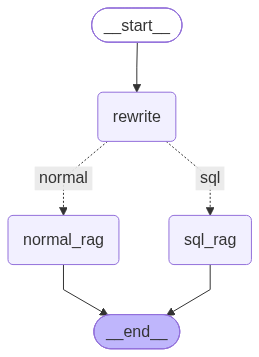

In [66]:
from IPython.display import Image, display

display(
    Image(
        app.get_graph().draw_mermaid_png()
    )
)

In [67]:
result = app.invoke({
    "question": "Generate a SQL query to retrieve the currency attribute from the cif_notification_subscription EDL table.",
    "standalone_question": "",
    "context": "",
    "answer": "",
    "chat_history": chat_history
})

print("Standalone question:")
print(result["standalone_question"])

print("\nContext:")
print(result["context"])

print("\nAnswer:")
print(result["answer"])

Standalone question:
Generate a SQL query to retrieve the currency attribute from the cif_notification_subscription EDL table.

Context:
Owner Business Object: CIF_NOTIFCN_SUBSCRPTN
Owner Object Attribute: amount_crncy
EDL Object Name: cif_notification_subscription
EDL Object Attribute: currency

Owner Business Object: CIF_CUSTOMER_RELATIONS
Owner Object Attribute: txn_currency
EDL Object Name: relation
EDL Object Attribute: transaction_limit_currency

Owner Business Object: PRODUCT_CURRENCY
Owner Object Attribute: CRNCY
EDL Object Name: product_currency
EDL Object Attribute: currency

Answer:
SELECT currency
FROM cif_notification_subscription;


In [162]:
#docs = vector_store.similarity_search(
    #"amount_crncy CIF_NOTIFCN_SUBSCRPTN",
    #k=10
#)

#for i, doc in enumerate(docs):
    #print(f"\n--- {i+1} ---")
    #print(doc.page_content)